# Log → linear: guessed curve vs. reference

1. Do the same as `src/main.py`: load the bracket, recover the curve with Debevec, fit the polynomial, linearize the middle image
2. Load the reference linear EXR exported from DaVinci Resolve
3. Compare: numbers (in stops), the curves, the images, and an error map

We also compare against the **official Gen 5 formula** as a second reference

In [41]:
import sys
import os
sys.path.append("src") # so importing main.py from the src folder is possible

import numpy as np
import cv2
import matplotlib.pyplot as plt
import main as m

FOLDER = "test_img/bmpcc6kg2/bracketing/tiff"
REFERENCE = "reference/A001_01032221_S028_lin.exr"

np.set_printoptions(precision=4, suppress=True)

## 1. Creating Look-up Table

In [42]:
files = m.find_images(FOLDER)
print(len(files), "images found")

times = m.get_exposure_times(FOLDER, files)
images = m.load_images(files)
print(f"Converted to {images[0].shape}, {images[0].dtype}")

11 images found
exposure times from metadata
A001_01032221_S023.tif  1/25 s
A001_01032221_S024.tif  1/30 s
A001_01032221_S025.tif  1/50 s
A001_01032221_S026.tif  1/60 s
A001_01032221_S027.tif  1/100 s
A001_01032221_S028.tif  1/125 s
A001_01032221_S029.tif  1/200 s
A001_01032221_S030.tif  1/250 s
A001_01032221_S031.tif  1/500 s
A001_01032221_S032.tif  1/1000 s
A001_01032221_S033.tif  1/2000 s
loaded A001_01032221_S023.tif
loaded A001_01032221_S024.tif
loaded A001_01032221_S025.tif
loaded A001_01032221_S026.tif
loaded A001_01032221_S027.tif
loaded A001_01032221_S028.tif
loaded A001_01032221_S029.tif
loaded A001_01032221_S030.tif
loaded A001_01032221_S031.tif
loaded A001_01032221_S032.tif
loaded A001_01032221_S033.tif
Converted to (3456, 6144, 3), uint8


In [43]:
lut = m.calculate_correction(images, times)
print("lut:", lut.shape, lut.dtype)

os.makedirs(os.path.join("output", "bmpcc6kg2"), exist_ok=True)
coefs = m.fit_polynomial(lut, os.path.join("output", "bmpcc6kg2", "model.yml"))
for name in "RGB":
    m.print_equation(name, coefs[name])

lut: (256, 1, 3) float32
R: linear = 4.8823 - 103.9372*y^1 + 904.1096*y^2 - 4156.0907*y^3 + 10908.0883*y^4 - 16259.7476*y^5 + 12667.4585*y^6 - 3842.4339*y^7
G: linear = -1.3094 + 28.4518*y^1 - 256.6621*y^2 + 1257.6570*y^3 - 3617.0263*y^4 + 6195.6859*y^5 - 5889.6624*y^6 + 2495.2337*y^7
B: linear = -6.5125 + 140.4123*y^1 - 1243.8187*y^2 + 5885.8438*y^3 - 16102.4252*y^4 + 25624.9691*y^5 - 22086.8373*y^6 + 8091.2645*y^7


In [44]:
middle = m.choose_middle_image(times)
img = images[middle] # 8-bit BGR, the log image
print("middle image:", os.path.basename(files[middle]))

guessed = m.apply_correction(img, lut) # linear, BGR, Debevec's own scale

middle image: A001_01032221_S028.tif


## 2. Load the reference and the official Gen 5

The EXR is stored as RGB, tets images are BGR -> so flip it

The Gen 5 version is made the same way: a 256-row table, then every pixel looks up its row

In [45]:
reference = m.read_exr(REFERENCE)[:, :, ::-1] # RGB -> BGR
print("reference:", reference.shape, reference.dtype, " min", reference.min(), " max", reference.max())

# Official Blackmagic Film Gen 5
A = 0.08692876065491224
B = 0.005494072432257808
C = 0.5300133392291939
D = 8.283605932402494
E = 0.09246575342465753
LOG_CUT = D * 0.005 + E

def gen5_to_linear(y):
    if y >= LOG_CUT:
        return np.exp((y - C) / A) - B
    else:
        return (y - E) / D

gen5_lut = np.zeros((256, 1, 3), dtype=np.float32) # same shape as Debevec's table
for level in range(256):
    for c in range(3):
        gen5_lut[level, 0, c] = gen5_to_linear(level / 255)

gen5 = m.apply_correction(img, gen5_lut)

reference: (3456, 6144, 3) float32  min -0.019906323  max 8.715691


## 3. Put everything on the same brightness

Debevec doesn't know the real brightness (its numbers have their own scale).
We only use pixels between levels 40 and 183, the range Debevec really measured.

In [46]:
# <40 - deep shadows mostly noise
# Gen 5's sensor clip it at log 0.718, which is level 183 in 8 bits
good = (img > 40) & (img < 183) # True/False for every pixel and channel

k = np.median(reference[good]) / np.median(guessed[good])
guessed = guessed * k
print("k =", k)

k = 0.70840293


## 4. Numbers: how many stops apart?

`stops = log2(a / b)`: 0 means identical, 1 means twice too bright, -1 means half.

In [47]:
def stops_apart(a, b):
    """Median and 95th percentile of |log2(a/b)|, per channel, only on good pixels."""
    print("        median    95%")
    for c, name in [(2, "R"), (1, "G"), (0, "B")]:
        mask = good[:, :, c] & (a[:, :, c] > 0) & (b[:, :, c] > 0)
        s = np.abs(np.log2(a[:, :, c][mask] / b[:, :, c][mask]))
        print(f"   {name}   {np.median(s):.3f}    {np.percentile(s, 95):.3f}")

print("guessed vs reference");  stops_apart(guessed, reference)
print("guessed vs Gen 5");      stops_apart(guessed, gen5 * (np.median(reference[good]) / np.median(gen5[good])))
print("Gen 5 vs reference");    stops_apart(gen5, reference)

guessed vs reference
        median    95%
   R   0.025    0.073
   G   0.024    0.074
   B   0.044    0.100
guessed vs Gen 5
        median    95%
   R   0.028    0.047
   G   0.028    0.068
   B   0.051    0.096
Gen 5 vs reference
        median    95%
   R   0.017    0.032
   G   0.017    0.032
   B   0.017    0.032


## 5. The curves

For every log level we take the median reference value of all pixels with that level (on a 4× smaller image, to be quick).
If the reference were pure linear Gen 5, the black dots would sit on the grey Gen 5 line.
The shaded parts are where Debevec had no real data.

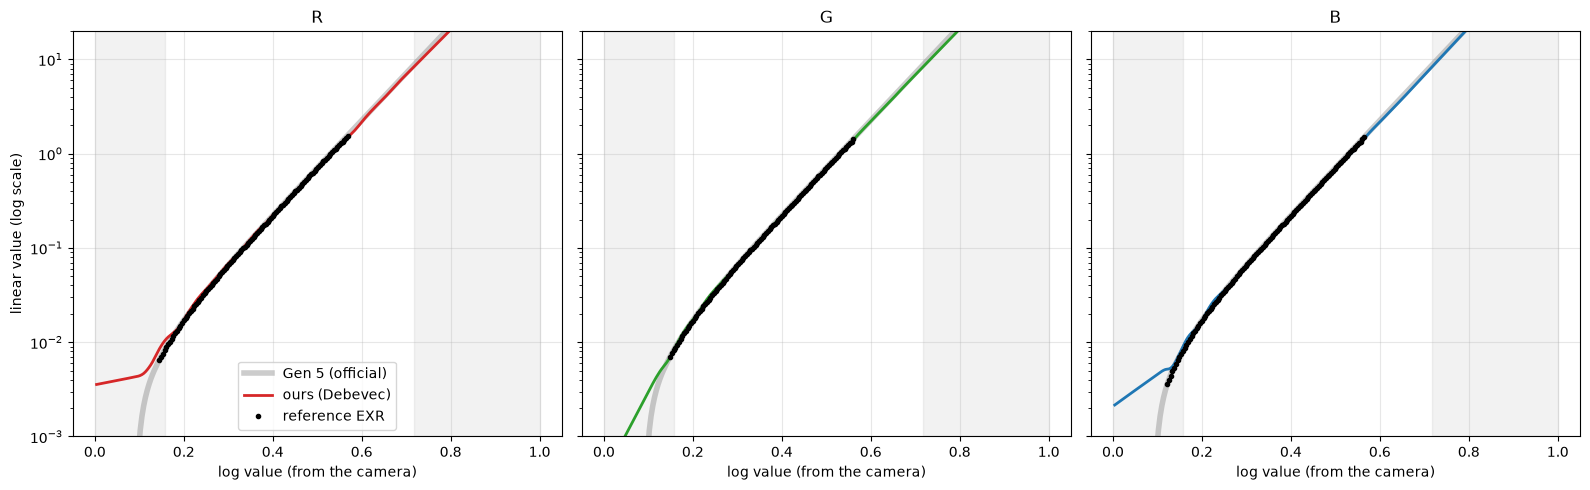

In [48]:
small_img = img[::4, ::4]
small_ref = reference[::4, ::4]
levels = np.arange(256)
x = levels / 255

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (c, name, color) in zip(axes, [(2, "R", "tab:red"), (1, "G", "tab:green"), (0, "B", "tab:blue")]):
    # reference: median per level
    ref_x, ref_y = [], []
    for level in levels:
        sel = small_img[:, :, c] == level
        if sel.sum() > 50:
            ref_x.append(level / 255)
            ref_y.append(np.median(small_ref[:, :, c][sel]))

    gen5_scaled = gen5_lut[:, 0, c] * (np.median(reference[good]) / np.median(gen5[good]))
    ax.plot(x[24:], gen5_scaled[24:], color="grey", linewidth=4, alpha=0.4, label="Gen 5 (official)")
    ax.plot(x[1:], lut[1:, 0, c] * k, color=color, linewidth=2, label="ours (Debevec)")
    ax.plot(ref_x, ref_y, "o", color="black", markersize=3, label="reference EXR")

    ax.axvspan(0, 40 / 255, color="grey", alpha=0.1)
    ax.axvspan(183 / 255, 1, color="grey", alpha=0.1)
    ax.set_yscale("log")
    ax.set_ylim(1e-3, 20)
    ax.set_title(name)
    ax.set_xlabel("log value (from the camera)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("linear value (log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. The images

Top row: **linear** values, just cut at 1, with no gamma. This is what linear data looks like on a screen: dark and contrasty.
Bottom row: the same, with **gamma 2.2** (`** (1/2.2)`), which is how it should be viewed.

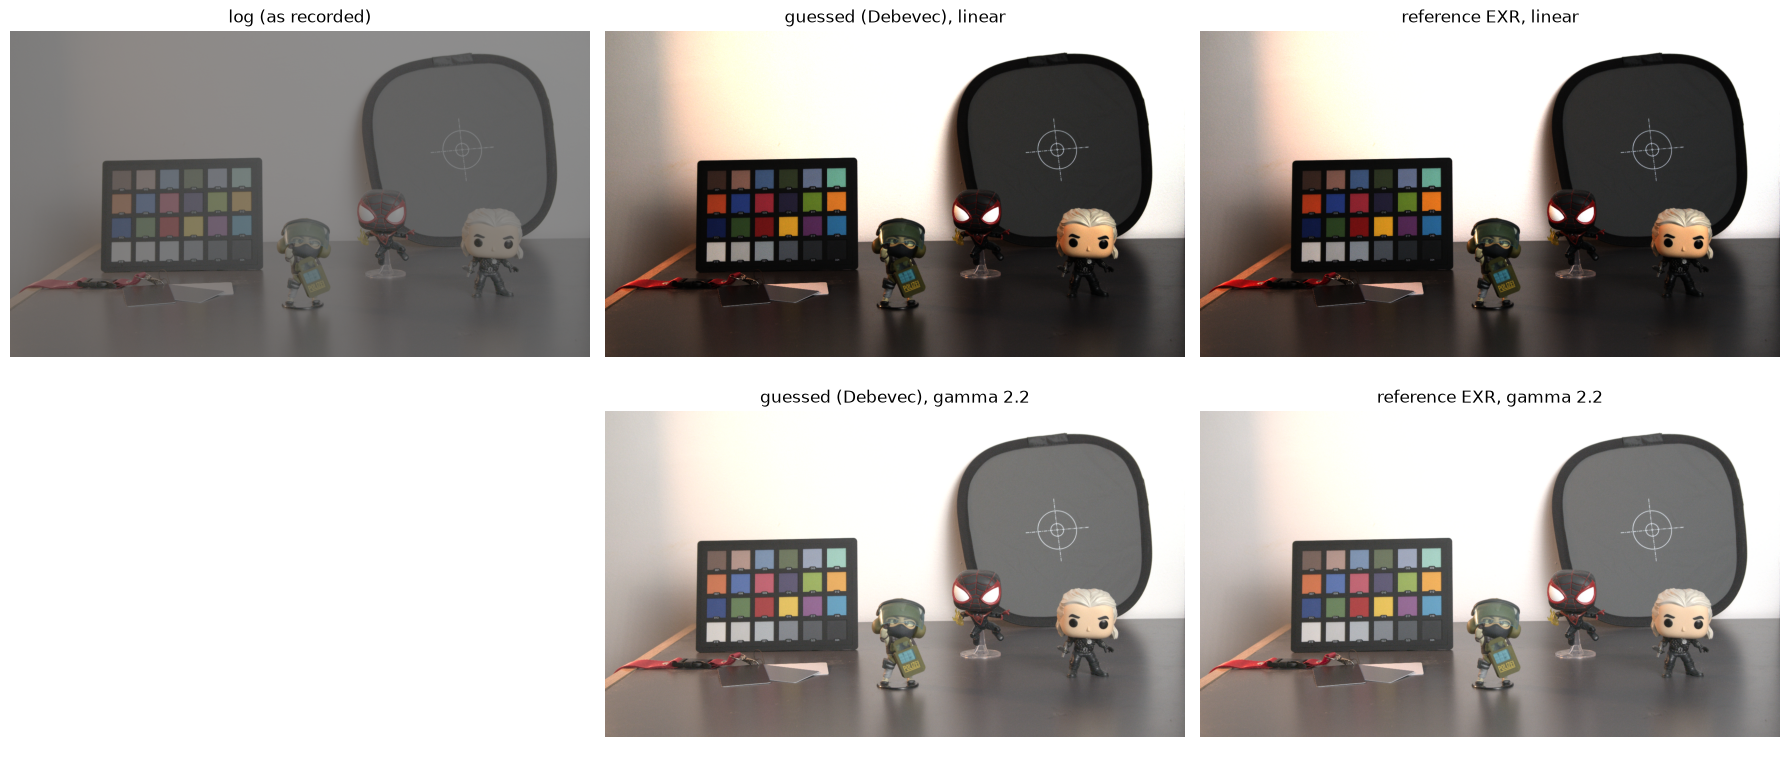

In [49]:
def small_rgb(lin_bgr):
    """4x smaller + BGR -> RGB for matplotlib, cut to 0..1"""
    return np.clip(lin_bgr[::4, ::4, ::-1], 0, 1)

def gamma22(lin):
    return lin ** (1 / 2.2)

fig, axes = plt.subplots(2, 3, figsize=(18, 8)) # 2 rows, 3 columns

axes[0, 0].imshow(img[::4, ::4, ::-1]);              axes[0, 0].set_title("log (as recorded)")
axes[0, 1].imshow(small_rgb(guessed));               axes[0, 1].set_title("guessed (Debevec), linear")
axes[0, 2].imshow(small_rgb(reference));             axes[0, 2].set_title("reference EXR, linear")

axes[1, 1].imshow(gamma22(small_rgb(guessed)));      axes[1, 1].set_title("guessed (Debevec), gamma 2.2")
axes[1, 2].imshow(gamma22(small_rgb(reference)));    axes[1, 2].set_title("reference EXR, gamma 2.2")

for ax in axes.ravel(): # ravel = all 6 panels in one list
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Error map

Green channel, ours vs reference, in stops. Red = ours brighter, blue = ours darker, white = equal.
Grey = pixels outside levels 40–183 (not compared).

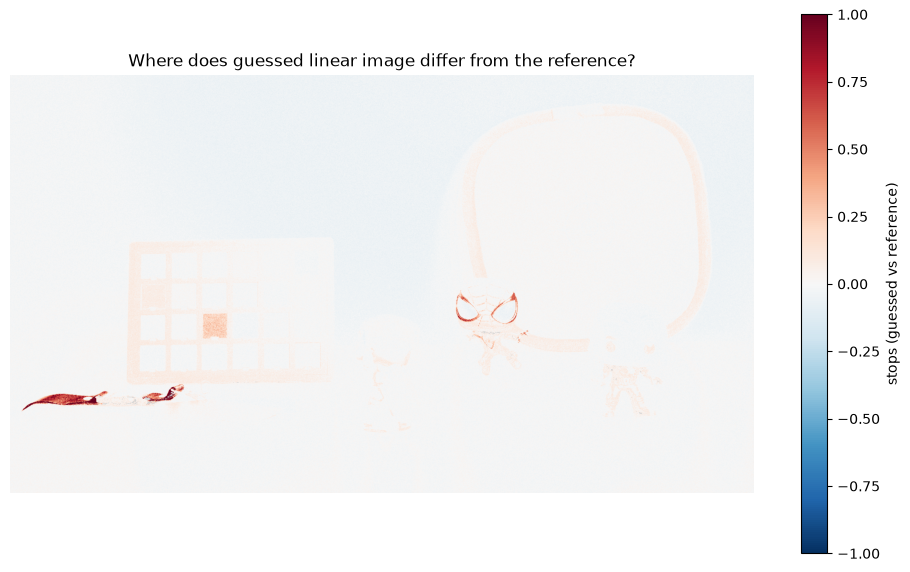

In [50]:
c = 1   # green
error = np.full(img.shape[:2], np.nan)                # NaN = not compared
mask = good[:, :, c] & (reference[:, :, c] > 0)
error[mask] = np.log2(guessed[:, :, c][mask] / reference[:, :, c][mask])

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("lightgrey")

plt.figure(figsize=(12, 7))
plt.imshow(error[::4, ::4], cmap=cmap, vmin=-1, vmax=1)
plt.colorbar(label="stops (guessed vs reference)")
plt.axis("off")
plt.title("Where does guessed linear image differ from the reference?")
plt.show()

## 8. Testing against unknown D-LOG M Curve

# DJI Action 4

Same steps for the DJI bracket. The DJI files have no metadata, so the exposure times come from `exposures.txt`.
Everything gets a `dji_` prefix, so the Blackmagic variables above stay untouched.

In [51]:
DJI_FOLDER = "test_img/djiaction4/bracketing/tiff"
DJI_OUT = os.path.join("output", "djiaction4")
os.makedirs(DJI_OUT, exist_ok=True)

dji_files = m.find_images(DJI_FOLDER)
print(len(dji_files), "images found")

dji_times = m.get_exposure_times(DJI_FOLDER, dji_files)
dji_images = m.load_images(dji_files)
print(f"Converted to {dji_images[0].shape}, {dji_images[0].dtype}")

19 images found
exposure times from test_img/djiaction4/bracketing/tiff/exposures.txt
DJI_20261121210316_0001.tif  1/25 s
DJI_20261121210329_0002.tif  1/30 s
DJI_20261121210337_0003.tif  1/40 s
DJI_20261121210346_0004.tif  1/50 s
DJI_20261121210356_0005.tif  1/60 s
DJI_20261121210405_0006.tif  1/80 s
DJI_20261121210414_0007.tif  1/100 s
DJI_20261121210423_0008.tif  1/120 s
DJI_20261121210431_0009.tif  1/160 s
DJI_20261121210440_0010.tif  1/200 s
DJI_20261121210449_0011.tif  1/240 s
DJI_20261121210458_0012.tif  1/320 s
DJI_20261121210507_0013.tif  1/400 s
DJI_20261121210515_0014.tif  1/500 s
DJI_20261121210524_0015.tif  1/640 s
DJI_20261121210533_0016.tif  1/800 s
DJI_20261121210544_0017.tif  1/1000 s
DJI_20261121210553_0018.tif  1/1250 s
DJI_20261121210602_0019.tif  1/1600 s
loaded DJI_20261121210316_0001.tif
loaded DJI_20261121210329_0002.tif
loaded DJI_20261121210337_0003.tif
loaded DJI_20261121210346_0004.tif
loaded DJI_20261121210356_0005.tif
loaded DJI_20261121210405_0006.tif
load

In [52]:
dji_lut = m.calculate_correction(dji_images, dji_times)
print("lut:", dji_lut.shape, dji_lut.dtype)

dji_coefs = m.fit_polynomial(dji_lut, os.path.join(DJI_OUT, "model.yml"))
for name in "RGB":
    m.print_equation(name, dji_coefs[name])

lut: (256, 1, 3) float32
R: linear = 0.6301 - 15.4532*y^1 + 157.0893*y^2 - 791.9025*y^3 + 2320.2409*y^4 - 3865.0833*y^5 + 3391.4808*y^6 - 1204.7208*y^7
G: linear = -1.4705 + 30.4432*y^1 - 250.8463*y^2 + 1121.6353*y^3 - 2810.9141*y^4 + 4030.4318*y^5 - 3089.5981*y^6 + 993.2608*y^7
B: linear = -0.5245 + 10.0992*y^1 - 72.4842*y^2 + 290.3886*y^3 - 580.2147*y^4 + 573.2347*y^5 - 216.8549*y^6 + 3.2447*y^7


## Consistency test (no reference needed)

Shots 3 positions apart are exactly 1 stop apart (1/3 stop per shot).
After linearizing, the brighter one must be exactly 2x the darker one.
If the curve is right, every error is close to 0 stops.

DJI clips at level 255 (not 183 like the Blackmagic), so we use levels 10-250.

In [56]:
def consistency_test(images, times, lut, step, lo, hi):
    """Linearize two shots 'step' apart. Their ratio must equal the exposure ratio."""
    errors = []
    for i in range(len(images) - step):
        j = i + step
        good = (images[i] > lo) & (images[i] < hi) & (images[j] > lo) & (images[j] < hi)
        a = m.apply_correction(images[i], lut)
        b = m.apply_correction(images[j], lut)
        measured = np.median(a[good] / b[good])
        expected = times[i] / times[j]
        error = np.log2(measured / expected)
        errors.append(abs(error))
        print(f"{i+1:2d} vs {j+1:2d}: expected x{expected:.2f}, measured x{measured:.2f}, error {error:+.3f} stops")
    print("median abs error:", round(float(np.median(errors)), 3), "stops,  worst:", round(float(max(errors)), 3))

consistency_test(dji_images, dji_times, dji_lut, step=3, lo=10, hi=250)

 1 vs  4: expected x2.00, measured x1.98, error -0.015 stops
 2 vs  5: expected x2.00, measured x1.99, error -0.006 stops
 3 vs  6: expected x2.00, measured x1.99, error -0.006 stops
 4 vs  7: expected x2.00, measured x1.99, error -0.008 stops
 5 vs  8: expected x2.00, measured x2.00, error -0.003 stops
 6 vs  9: expected x2.00, measured x1.99, error -0.009 stops
 7 vs 10: expected x2.00, measured x1.99, error -0.009 stops
 8 vs 11: expected x2.00, measured x1.99, error -0.010 stops
 9 vs 12: expected x2.00, measured x2.01, error +0.007 stops
10 vs 13: expected x2.00, measured x2.01, error +0.010 stops
11 vs 14: expected x2.08, measured x2.10, error +0.013 stops
12 vs 15: expected x2.00, measured x2.00, error -0.001 stops
13 vs 16: expected x2.00, measured x1.99, error -0.006 stops
14 vs 17: expected x2.00, measured x1.97, error -0.021 stops
15 vs 18: expected x1.95, measured x1.96, error +0.003 stops
16 vs 19: expected x2.00, measured x2.00, error -0.003 stops
median abs error: 0.007 

## The curve

Debevec's table for each channel. Unlike the Blackmagic, the DJI has real data up to level 255.

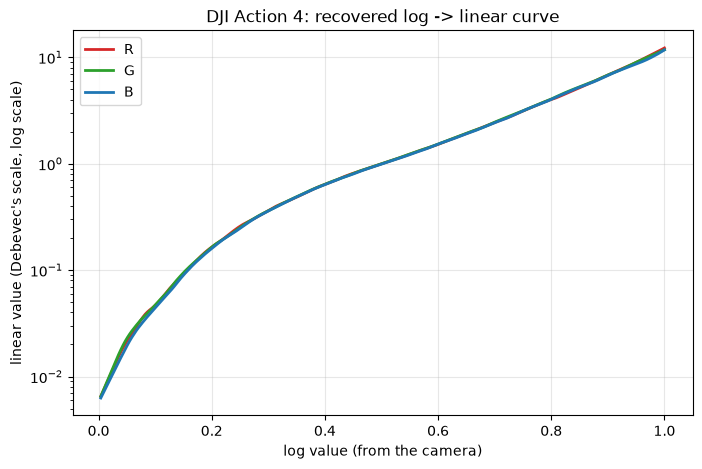

In [ ]:
x = np.arange(256) / 255

plt.figure(figsize=(8, 5))
for c, name, color in [(2, "R", "tab:red"), (1, "G", "tab:green"), (0, "B", "tab:blue")]:
    plt.plot(x[1:], dji_lut[1:, 0, c], color=color, linewidth=2, label=name)
plt.yscale("log")
plt.xlabel("log value (from the camera)")
plt.ylabel("linear value (Debevec's scale, log scale)")
plt.title("DJI Action 4: recovered log -> linear curve")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Middle image: linearize, save, look

The middle exposure is linearized, brightness set with `auto_exposure` (median = 0.18), then saved

middle image: DJI_20261121210440_0010.tif
saved to output/djiaction4


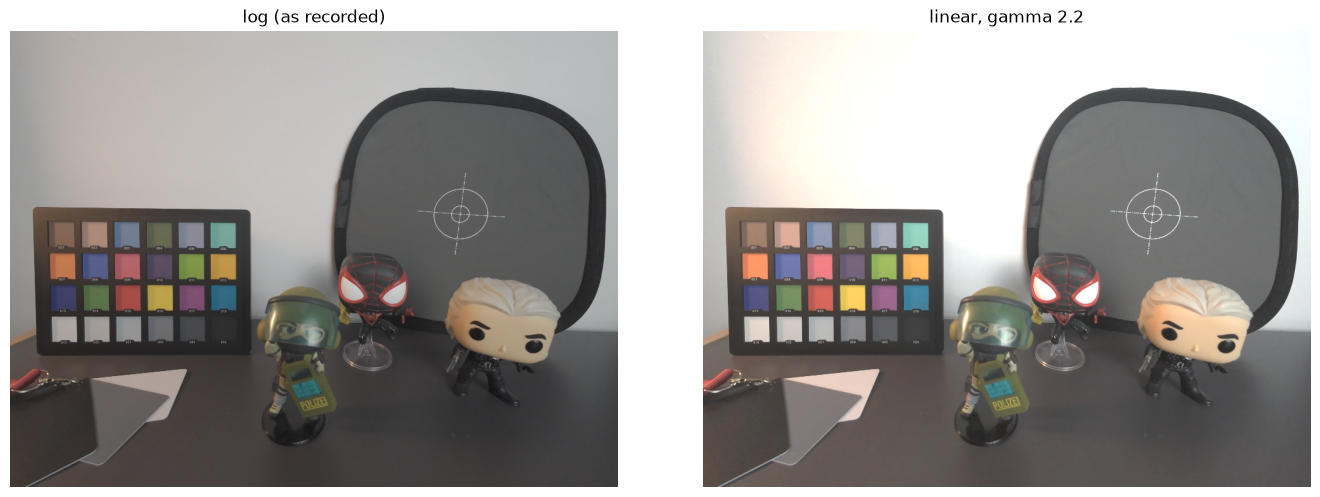

In [55]:
dji_middle = m.choose_middle_image(dji_times)
dji_img = dji_images[dji_middle]
print("middle image:", os.path.basename(dji_files[dji_middle]))

dji_linear = m.auto_exposure(m.apply_correction(dji_img, dji_lut))

name = os.path.splitext(os.path.basename(dji_files[dji_middle]))[0]
m.save_linear_exr(os.path.join(DJI_OUT, name + "_lin.exr"), dji_linear)
m.save_gamma22_tiff(os.path.join(DJI_OUT, name + "_g22.tif"), dji_linear)
print("saved to", DJI_OUT)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(dji_img[::4, ::4, ::-1]);                 axes[0].set_title("log (as recorded)")
axes[1].imshow(gamma22(small_rgb(dji_linear)));          axes[1].set_title("linear, gamma 2.2")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()